In [1]:
library(plm)
library(lmtest)
library(lme4)
library(survival)

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric


Loading required package: Matrix



In [9]:
data=read.csv('paper_fixed_data.csv')

In [10]:
head(data)

,X,id,year,dis,cluster_id,role,Code,gender,yfp,npub,F,L,M,ST
,<int>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<chr>
1,0,29768070,2008,51,20009795,F,JPN,F,2008,5,2,0,0,Advanced
2,1,31240446,2008,51,20009795,F,JPN,F,2008,5,2,0,0,Advanced
3,2,29768070,2008,51,29411586,M,JPN,M,2000,74,3,0,5,Advanced
4,3,31240446,2008,51,29411586,M,JPN,M,2000,74,3,0,5,Advanced
5,4,43269102,2015,51,29411586,M,JPN,M,2000,74,3,0,5,Advanced
6,5,45225060,2016,58,29411586,M,JPN,M,2000,74,3,0,5,Advanced


In [11]:
data$npub=log(data$npub)

In [12]:
data$fdep=ifelse(data$role == 'F', 1, 0)
data$ldep=ifelse(data$role == 'L', 1, 0)

In [13]:
unique_ids=unique(data$id)

In [14]:
sample_id=sample(unique_ids,50000)
sample_data=data[data$id %in% sample_id,]

In [15]:
fixed=plm(fdep~gender+npub+ST,data = sample_data, index=c('id'), model = "within")

In [16]:
summary(fixed)

Oneway (individual) effect Within Model

Call:
plm(formula = fdep ~ gender + npub + ST, data = sample_data, 
    model = "within", index = c("id"))

Unbalanced Panel: n = 50000, T = 1-2223, N = 408737

Residuals:
      Min.    1st Qu.     Median    3rd Qu.       Max. 
-1.1031898 -0.1542023 -0.0629673  0.0098152  1.0775474 

Coefficients:
             Estimate  Std. Error t-value  Pr(>|t|)    
genderM   -0.02473986  0.00130447 -18.965 < 2.2e-16 ***
npub      -0.02244976  0.00038704 -58.004 < 2.2e-16 ***
STLagging  0.04844732  0.00130729  37.059 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Total Sum of Squares:    38609
Residual Sum of Squares: 37926
R-Squared:      0.017708
Adj. R-Squared: -0.11921
F-statistic: 2155.69 on 3 and 358734 DF, p-value: < 2.22e-16

In [17]:
fixed=plm(ldep~gender+npub+ST,data = sample_data,index=c('id'),model = "within")

In [18]:
summary(fixed)

Oneway (individual) effect Within Model

Call:
plm(formula = ldep ~ gender + npub + ST, data = sample_data, 
    model = "within", index = c("id"))

Unbalanced Panel: n = 50000, T = 1-2223, N = 408737

Residuals:
     Min.   1st Qu.    Median   3rd Qu.      Max. 
-0.853362 -0.162910 -0.058550  0.022332  1.267646 

Coefficients:
             Estimate  Std. Error t-value  Pr(>|t|)    
genderM    0.02110494  0.00127651  16.533 < 2.2e-16 ***
npub       0.04788108  0.00037874 126.420 < 2.2e-16 ***
STLagging -0.03124155  0.00127927 -24.421 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Total Sum of Squares:    38290
Residual Sum of Squares: 36317
R-Squared:      0.051531
Adj. R-Squared: -0.080671
F-statistic: 6496.77 on 3 and 358734 DF, p-value: < 2.22e-16

In [19]:
fitclogit=clogit(fdep~gender+npub+ST+strata(id),data = sample_data)

In [20]:
summary(fitclogit)

Call:
coxph(formula = Surv(rep(1, 408737L), fdep) ~ gender + npub + 
    ST + strata(id), data = sample_data, method = "exact")

  n= 408737, number of events= 52528 

               coef exp(coef)  se(coef)      z Pr(>|z|)    
genderM   -0.237301  0.788754  0.012129 -19.57   <2e-16 ***
npub      -0.203805  0.815622  0.003619 -56.31   <2e-16 ***
STLagging  0.417037  1.517459  0.012032  34.66   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

          exp(coef) exp(-coef) lower .95 upper .95
genderM      0.7888      1.268    0.7702    0.8077
npub         0.8156      1.226    0.8099    0.8214
STLagging    1.5175      0.659    1.4821    1.5537

Concordance= 0.585  (se = 0.003 )
Likelihood ratio test= 6075  on 3 df,   p=<2e-16
Wald test            = 5815  on 3 df,   p=<2e-16
Score (logrank) test = 6052  on 3 df,   p=<2e-16


In [21]:
fitclogit=clogit(ldep~gender+npub+ST+strata(id),data = sample_data)

In [22]:
summary(fitclogit)

Call:
coxph(formula = Surv(rep(1, 408737L), ldep) ~ gender + npub + 
    ST + strata(id), data = sample_data, method = "exact")

  n= 408737, number of events= 52977 

               coef exp(coef)  se(coef)      z Pr(>|z|)    
genderM    0.222473  1.249162  0.013907  16.00   <2e-16 ***
npub       0.509175  1.663917  0.004578 111.23   <2e-16 ***
STLagging -0.213333  0.807887  0.012385 -17.23   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

          exp(coef) exp(-coef) lower .95 upper .95
genderM      1.2492     0.8005    1.2156    1.2837
npub         1.6639     0.6010    1.6491    1.6789
STLagging    0.8079     1.2378    0.7885    0.8277

Concordance= 0.709  (se = 0.003 )
Likelihood ratio test= 18700  on 3 df,   p=<2e-16
Wald test            = 14648  on 3 df,   p=<2e-16
Score (logrank) test = 16839  on 3 df,   p=<2e-16


In [25]:
# Load the necessary libraries
library(MASS)  # for the clogit() function

# Simulate data
set.seed(123)
agegp <- rep(1:4, each = 10)
age <- rnorm(40, mean = 40, sd = 10)
smoke <- rep(0:1, each = 20)
case <- rbinom(40, size = 1, prob = plogis(-0.5 + 0.1*age + 0.2*smoke - 0.1*age*smoke))
lung <- data.frame(agegp, age, smoke, case)

# Fit a conditional logistic regression model
model <- clogit(case ~ age + smoke + age:smoke+strata(agegp), data = lung)

# Make predictions for new data
newdata <- data.frame(agegp = rep(1, 2),
                      age = c(30, 50),
                      smoke = c(0, 1))
pred <- predict(model, type = "risk")

# Show the predicted probabilities
pred


1         2         3         4         5         6         7         8 
1.3154716 1.1406452 0.5269077 1.0017791 0.9766768 0.4925129 0.8463900 1.7831639 
        9        10        11        12        13        14        15        16 
1.3892398 1.2518547 0.6450618 0.9368100 0.9203902 1.0431905 1.3910310 0.5059067 
       17        18        19        20        21        22        23        24 
0.8826117 2.5577453 0.8083741 1.3420386 1.0510748 0.9841298 1.0476765 1.0238468 
       25        26        27        28        29        30        31        32 
1.0156460 1.1026731 0.9068722 0.9562327 1.0568134 0.8781216 0.9919465 1.0489486 
       33        34        35        36        37        38        39        40 
0.9565920 0.9578515 0.9620555 0.9720107 0.9822044 1.0301793 1.0498336 1.0559085

In [22]:
?predict.coxph


predict.coxph {survival},R Documentation
object,the results of a coxph fit.
newdata,"Optional new data at which to do predictions. If absent predictions are for the data frame used in the original fit. When coxph has been called with a formula argument created in another context, i.e., coxph has been called within another function and the formula was passed as an argument to that function, there can be problems finding the data set. See the note below."
type,"the type of predicted value. Choices are the linear predictor (""lp""), the risk score exp(lp) (""risk""), the expected number of events given the covariates and follow-up time (""expected""), and the terms of the linear predictor (""terms""). The survival probability for a subject is equal to exp(-expected)."
se.fit,"if TRUE, pointwise standard errors are produced for the predictions."
na.action,"applies only when the newdata argument is present, and defines the missing value action for the new data. The default is to include all observations. When there is no newdata, then the behavior of missing is dictated by the na.action option of the original fit."
terms,"if type=""terms"", this argument can be used to specify which terms should be included; the default is all."
collapse,"optional vector of subject identifiers. If specified, the output will contain one entry per subject rather than one entry per observation."
reference,"reference for centering predictions, see details below"
...,For future methods


In [11]:
pred_prob

  age group emmean   SE  df asymp.LCL asymp.UCL
 52.5     1   -225 72.7 Inf      -367     -82.4
 52.5     2   -938 91.3 Inf     -1117    -758.9

Results are averaged over the levels of: id 
Results are given on the log (not the response) scale. 
Confidence level used: 0.95 

In [17]:
newdat2

sex,age,group,outcome
<chr>,<dbl>,<chr>,<dbl>
male,40.00000,A,0.3788292
male,40.20202,A,0.3788292
male,40.40404,A,0.3788292
male,40.60606,A,0.3788292
male,40.80808,A,0.3788292
male,41.01010,A,0.3788292
male,41.21212,A,0.3788292
male,41.41414,A,0.3788292
male,41.61616,A,0.3788292


Warning message in coxexact.fit(X, Y, istrat, offset, init, control, weights = weights, :
“Ran out of iterations and did not converge”


Call:
coxph(formula = Surv(rep(1, 100L), outcome) ~ sex * age + strata(group), 
    data = dat, method = "exact")

  n= 100, number of events= 6 

                  coef  exp(coef)   se(coef)      z Pr(>|z|)
sexmale      1.873e+02  2.206e+81  1.900e+02  0.986    0.324
age          3.644e+00  3.823e+01  1.030e+01  0.354    0.724
sexmale:age -3.644e+00  2.615e-02  4.044e+00 -0.901    0.368

            exp(coef) exp(-coef) lower .95  upper .95
sexmale     2.206e+81  4.534e-82 3.837e-81 1.268e+243
age         3.823e+01  2.615e-02 6.499e-08  2.250e+10
sexmale:age 2.615e-02  3.823e+01 9.440e-06  7.246e+01

Concordance= 1  (se = 0 )
Likelihood ratio test= 28.6  on 3 df,   p=3e-06
Wald test            = 1.91  on 3 df,   p=0.6
Score (logrank) test = 22.33  on 3 df,   p=6e-05


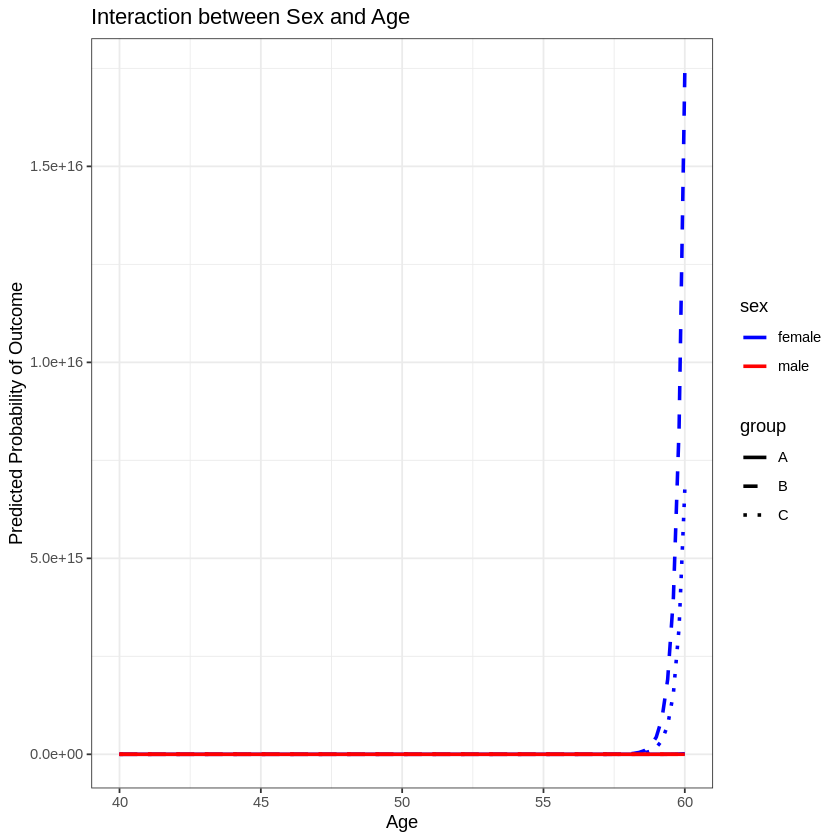

In [14]:
# Load the necessary libraries
library(ggplot2)  # for plotting

# Create a dataset with two categorical variables and a continuous variable
set.seed(123)
n <- 100
dat <- data.frame(
  group = sample(c("A", "B", "C"), n, replace = TRUE),
  sex = sample(c("male", "female"), n, replace = TRUE),
  age = rnorm(n, mean = 50, sd = 10)
)

# Create a binary outcome variable
dat$outcome <- ifelse(dat$group == "C" & dat$sex == "female" & dat$age > 55, 1, 0)

# Run a conditional logistic regression with an interaction term
model <- clogit(outcome ~ sex * age+strata(group), data = dat, )

# Get the estimated coefficients and p-values
summary(model)

# Create a data frame with the predicted probabilities for different levels of 'sex' and 'age'
newdat <- data.frame(
  sex = rep(c("male", "female"), each = 100),
  age = rep(seq(40, 60, length.out = 100), times = 2),
  group = "A"
)
newdat$outcome <- predict(model, newdat, type = "risk")

# Add the predicted probabilities for different levels of 'group'
newdat2 <- rbind(newdat, transform(newdat, group = "B"), transform(newdat, group = "C"))
newdat2$outcome <- predict(model, newdat2, type = "risk")

# Plot the interaction between 'sex' and 'age'
ggplot(newdat2, aes(x = age, y = outcome, color = sex, linetype = group)) +
  geom_line(size = 1) +
  scale_color_manual(values = c("blue", "red")) +
  scale_linetype_manual(values = c("solid", "dashed", "dotted")) +
  xlab("Age") + ylab("Predicted Probability of Outcome") +
  ggtitle("Interaction between Sex and Age") +
  theme_bw()
